<a href="https://colab.research.google.com/github/Manjot0005/data266-6359/blob/hw9/hw9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Latent Diffusion on Fashion-MNIST
### VAE latent space · forward diffusion · conditional U-Net (self- + cross-attention) · classifier-free guidance



In [1]:
# Install dependencies (Colab already has torch / torchvision / matplotlib / scipy)
%pip install -q diffusers accelerate safetensors

In [2]:
import os, math, time, copy, random, platform
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

# ----------------------------- configuration (single source of truth)
CFG = dict(
    seed            = 42,
    img_size        = 128,        # 28x28 FMNIST is upsampled -> VAE (/8) gives 16x16x4 latents
    vae_id          = "stabilityai/sd-vae-ft-mse",
    latent_scale    = 0.18215,    # standard SD VAE latent scaling factor
    T               = 1000,       # diffusion timesteps
    beta_start      = 1e-4,
    beta_end        = 0.02,       # linear schedule
    base_ch         = 64,
    ch_mults        = (1, 2, 4),
    num_res_blocks  = 2,
    attn_res        = (16,),      # self-attention at 16x16 (+ bottleneck always)
    emb_dim         = 256,        # time / label embedding width
    ctx_tokens      = 4,          # label context tokens for cross-attention
    use_cross_attn  = True,
    dropout         = 0.1,
    num_classes     = 10,
    p_uncond        = 0.1,        # label dropout probability (CFG training)
    epochs          = 50,
    lr              = 2e-5,
    batch_size      = 128,
    ema_decay       = 0.999,
    guidance_scale  = 3.0,        # w in eps = eps_u + w (eps_c - eps_u)
    out_dir         = "ldm_outputs",
)
NULL_LABEL = CFG["num_classes"]   # index 10 = "no label"
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
os.makedirs(CFG["out_dir"], exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__}")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (training will be very slow)")
for k, v in CFG.items(): print(f"  {k:15s} = {v}")

Python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130
Device: cuda | Tesla T4
  seed            = 42
  img_size        = 128
  vae_id          = stabilityai/sd-vae-ft-mse
  latent_scale    = 0.18215
  T               = 1000
  beta_start      = 0.0001
  beta_end        = 0.02
  base_ch         = 64
  ch_mults        = (1, 2, 4)
  num_res_blocks  = 2
  attn_res        = (16,)
  emb_dim         = 256
  ctx_tokens      = 4
  use_cross_attn  = True
  dropout         = 0.1
  num_classes     = 10
  p_uncond        = 0.1
  epochs          = 50
  lr              = 2e-05
  batch_size      = 128
  ema_decay       = 0.999
  guidance_scale  = 3.0
  out_dir         = ldm_outputs


100%|██████████| 26.4M/26.4M [00:00<00:00, 113MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 5.83MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 61.0MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.1MB/s]


train: 60000  test: 10000
class counts (train): {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}


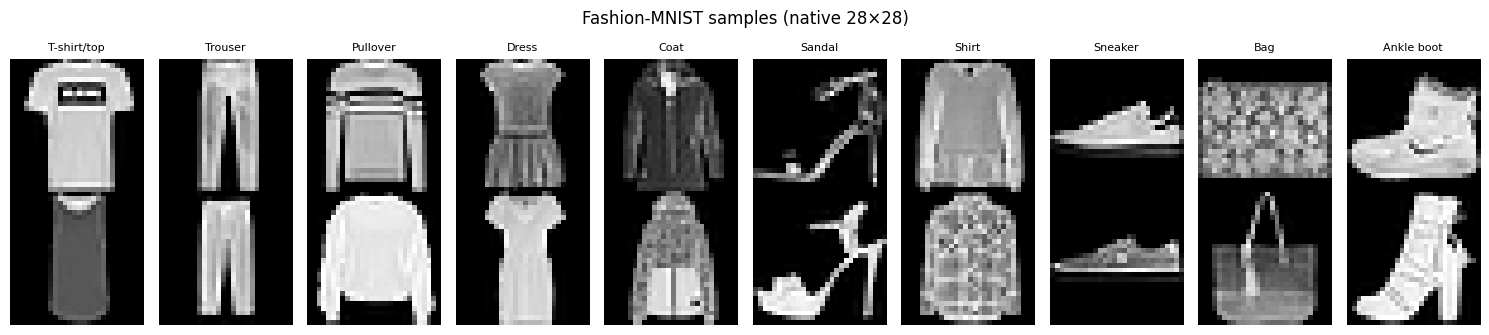

In [3]:
# ----------------------------- dataset
tfm = transforms.Compose([
    transforms.Resize((CFG["img_size"], CFG["img_size"]), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),                       # [0,1]
    transforms.Normalize([0.5], [0.5]),          # [-1,1]  (VAE input range)
])
train_set = datasets.FashionMNIST("data", train=True,  download=True, transform=tfm)
test_set  = datasets.FashionMNIST("data", train=False, download=True, transform=tfm)
raw_test  = datasets.FashionMNIST("data", train=False, download=True, transform=transforms.ToTensor())  # native 28x28

print(f"train: {len(train_set)}  test: {len(test_set)}")
counts = torch.bincount(train_set.targets, minlength=10)
print("class counts (train):", dict(zip(CLASSES, counts.tolist())))

fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    idx = (train_set.targets == c).nonzero()[:2, 0]
    for r in range(2):
        axes[r, c].imshow(train_set.data[idx[r]], cmap="gray"); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=8)
plt.suptitle("Fashion-MNIST samples (native 28×28)"); plt.tight_layout(); plt.show()

## 1 — VAE compression & latent representation

The pretrained KL-VAE `stabilityai/sd-vae-ft-mse` maps an RGB image $x\in\mathbb{R}^{3\times H\times W}$ to a latent $\mathbb{R}^{4\times H/8\times W/8}$.
Fashion-MNIST is grayscale, so each image is upsampled to 128×128 and the channel is repeated 3× → latents of shape **4×16×16**.

Latents are scaled by the standard factor $s = 0.18215$ so they have roughly unit variance:
$$z_0 = s\cdot \mathcal{E}(x), \qquad \hat x = \mathcal{D}(z_0 / s)$$

We use the posterior mean of $q(z\mid x)$ as the deterministic encoding.

In [4]:
from diffusers import AutoencoderKL

vae = AutoencoderKL.from_pretrained(CFG["vae_id"]).to(device).eval()
vae.requires_grad_(False)
SCALE = CFG["latent_scale"]
print("VAE config scaling_factor:", vae.config.scaling_factor, "| using:", SCALE)
print(f"VAE params: {sum(p.numel() for p in vae.parameters())/1e6:.1f}M (frozen)")

@torch.no_grad()
def vae_encode(x):
    # x: (B,1,H,W) in [-1,1]  ->  scaled latent (B,4,H/8,W/8)
    x = x.to(device).repeat(1, 3, 1, 1)
    return vae.encode(x).latent_dist.mean * SCALE

@torch.no_grad()
def vae_decode(z, chunk=64):
    # scaled latent -> grayscale image (B,1,H,W) in [-1,1]
    outs = []
    for zc in z.split(chunk):
        x = vae.decode(zc.to(device) / SCALE).sample
        outs.append(x.clamp(-1, 1).mean(1, keepdim=True))
    return torch.cat(outs)

to01 = lambda x: (x + 1) / 2
to28 = lambda x: F.interpolate(x, size=28, mode="area")   # back to native resolution

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

VAE config scaling_factor: 0.18215 | using: 0.18215
VAE params: 83.7M (frozen)


In [5]:
# ----------------------------- encode + cache the whole dataset once
LATENT_CACHE = os.path.join(CFG["out_dir"], f"latents_{CFG['img_size']}.pt")

@torch.no_grad()
def encode_dataset(ds, bs=256):
    zs, ys = [], []
    for x, y in DataLoader(ds, batch_size=bs, shuffle=False, num_workers=2):
        zs.append(vae_encode(x).cpu()); ys.append(y)
    return torch.cat(zs), torch.cat(ys)

if os.path.exists(LATENT_CACHE):
    cache = torch.load(LATENT_CACHE)
    print("Loaded cached latents.")
else:
    t0 = time.time()
    ztr, ytr = encode_dataset(train_set)
    zte, yte = encode_dataset(test_set)
    cache = dict(z_train=ztr, y_train=ytr, z_test=zte, y_test=yte)
    torch.save(cache, LATENT_CACHE)
    print(f"Encoded {len(ztr)+len(zte)} images in {time.time()-t0:.0f}s")

z_train, y_train, z_test, y_test = cache["z_train"], cache["y_train"], cache["z_test"], cache["y_test"]
LATENT_SHAPE = tuple(z_train.shape[1:])
print("latent shape:", LATENT_SHAPE)
print(f"scaled latent stats (train): mean={z_train.mean():.4f}  std={z_train.std():.4f}  "
      f"min={z_train.min():.2f}  max={z_train.max():.2f}")
print("per-channel std:", [round(v, 3) for v in z_train.std(dim=(0, 2, 3)).tolist()])

Encoded 70000 images in 969s
latent shape: (4, 16, 16)
scaled latent stats (train): mean=-0.0396  std=1.2724  min=-4.44  max=5.97
per-channel std: [1.154, 1.385, 0.601, 0.719]


Reconstruction MSE on 2000 test images (pixel range [0,1]):
  128×128 VAE input vs. reconstruction      : 0.00016   (PSNR 38.06 dB)
  28×28 (downsampled) vs. downsampled recon : 0.00005   (PSNR 42.88 dB)
  native 28×28 original vs. downsampled recon: 0.00219


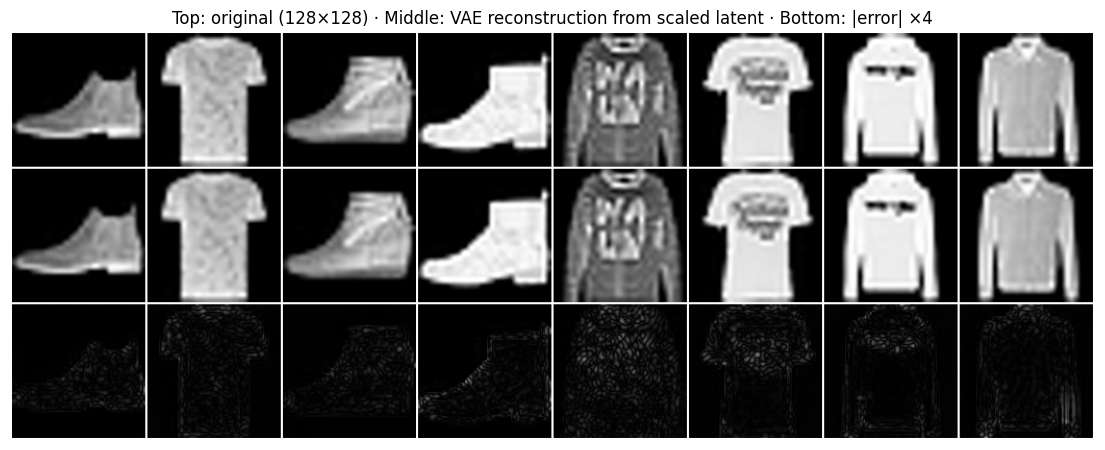

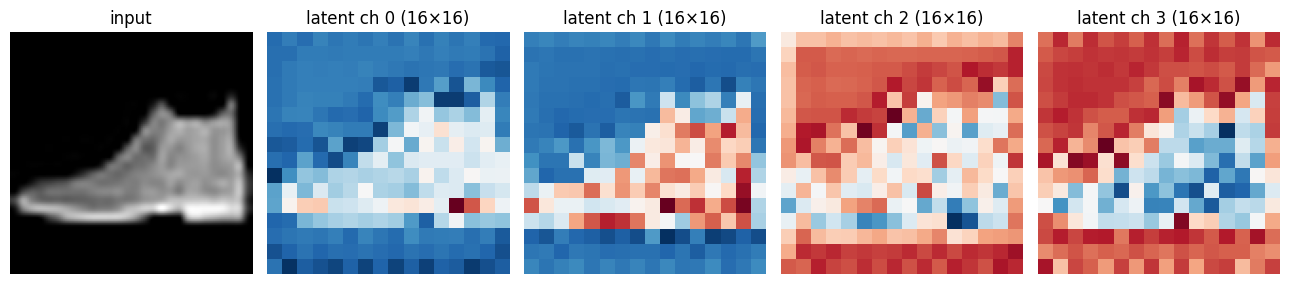

In [6]:
# ----------------------------- reconstruction check: MSE(decoded, original)
@torch.no_grad()
def recon_mse(n=2000, bs=200):
    se128, se28, se28_raw, cnt = 0., 0., 0., 0
    for i in range(0, n, bs):
        x = torch.stack([test_set[j][0] for j in range(i, i + bs)]).to(device)        # (B,1,128,128) in [-1,1]
        xr = torch.stack([raw_test[j][0] for j in range(i, i + bs)]).to(device)       # (B,1,28,28)  in [0,1]
        xh = vae_decode(z_test[i:i + bs].to(device))
        se128   += F.mse_loss(to01(xh), to01(x), reduction="sum").item()
        se28    += F.mse_loss(to28(to01(xh)), to28(to01(x)), reduction="sum").item()
        se28_raw+= F.mse_loss(to28(to01(xh)), xr, reduction="sum").item()
        cnt += len(x)
    return se128 / (cnt * 128 * 128), se28 / (cnt * 28 * 28), se28_raw / (cnt * 28 * 28)

mse128, mse28, mse28raw = recon_mse()
print(f"Reconstruction MSE on 2000 test images (pixel range [0,1]):")
print(f"  128×128 VAE input vs. reconstruction      : {mse128:.5f}   (PSNR {10*math.log10(1/mse128):.2f} dB)")
print(f"  28×28 (downsampled) vs. downsampled recon : {mse28:.5f}   (PSNR {10*math.log10(1/mse28):.2f} dB)")
print(f"  native 28×28 original vs. downsampled recon: {mse28raw:.5f}")

idx = torch.arange(8) * 125
x  = torch.stack([test_set[i][0] for i in idx.tolist()])
xh = vae_decode(z_test[idx].to(device)).cpu()
grid = make_grid(torch.cat([to01(x), to01(xh), (to01(x) - to01(xh)).abs() * 4]), nrow=8, pad_value=1)
plt.figure(figsize=(14, 5.5)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
plt.title("Top: original (128×128) · Middle: VAE reconstruction from scaled latent · Bottom: |error| ×4")
plt.savefig(f"{CFG['out_dir']}/vae_reconstruction.png", dpi=120, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
axes[0].imshow(to01(x[0, 0]), cmap="gray"); axes[0].set_title("input"); axes[0].axis("off")
for c in range(4):
    axes[c + 1].imshow(z_test[idx[0], c], cmap="RdBu_r"); axes[c + 1].set_title(f"latent ch {c} (16×16)"); axes[c + 1].axis("off")
plt.tight_layout(); plt.show()

## 2 — Forward diffusion in latent space

The forward process adds Gaussian noise directly to latents:
$$q(z_t\mid z_{t-1}) = \mathcal{N}\big(\sqrt{1-\beta_t}\,z_{t-1},\ \beta_t I\big),\qquad
q(z_t\mid z_0) = \mathcal{N}\big(\sqrt{\bar\alpha_t}\,z_0,\ (1-\bar\alpha_t) I\big)$$
with $\alpha_t = 1-\beta_t$, $\bar\alpha_t=\prod_{s\le t}\alpha_s$, $T = 1000$ and a linear schedule $\beta_t \in [10^{-4}, 0.02]$.
Closed-form noise injection: $z_t = \sqrt{\bar\alpha_t}\,z_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\ \epsilon\sim\mathcal N(0,I)$.

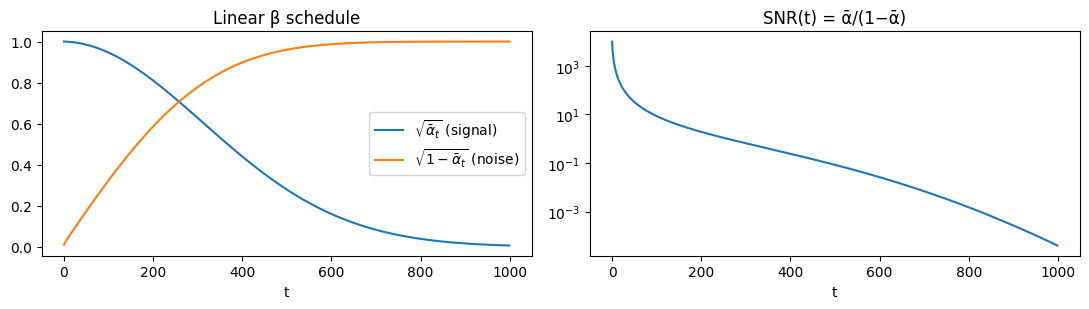

In [7]:
T = CFG["T"]
betas      = torch.linspace(CFG["beta_start"], CFG["beta_end"], T, dtype=torch.float64)
alphas     = 1.0 - betas
alpha_bars = torch.cumprod(alphas, 0)
alpha_bars_prev = torch.cat([torch.ones(1, dtype=torch.float64), alpha_bars[:-1]])
post_var   = betas * (1 - alpha_bars_prev) / (1 - alpha_bars)        # posterior variance  \tilde beta_t

# float32 copies on device for training / sampling
sched = {k: v.float().to(device) for k, v in dict(
    betas=betas, alphas=alphas, alpha_bars=alpha_bars, post_var=post_var).items()}

def q_sample(z0, t, noise=None):
    # Noise injection: sample z_t ~ q(z_t | z_0) in closed form.  t: LongTensor (B,) in [0, T-1]
    if noise is None:
        noise = torch.randn_like(z0)
    ab = sched["alpha_bars"].to(z0.device)[t].view(-1, 1, 1, 1)
    return ab.sqrt() * z0 + (1 - ab).sqrt() * noise, noise

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(alpha_bars.sqrt(), label=r"$\sqrt{\bar\alpha_t}$ (signal)"); ax[0].plot((1 - alpha_bars).sqrt(), label=r"$\sqrt{1-\bar\alpha_t}$ (noise)")
ax[0].set_xlabel("t"); ax[0].legend(); ax[0].set_title("Linear β schedule")
ax[1].semilogy(alpha_bars / (1 - alpha_bars)); ax[1].set_xlabel("t"); ax[1].set_title("SNR(t) = ᾱ/(1−ᾱ)")
plt.tight_layout(); plt.show()

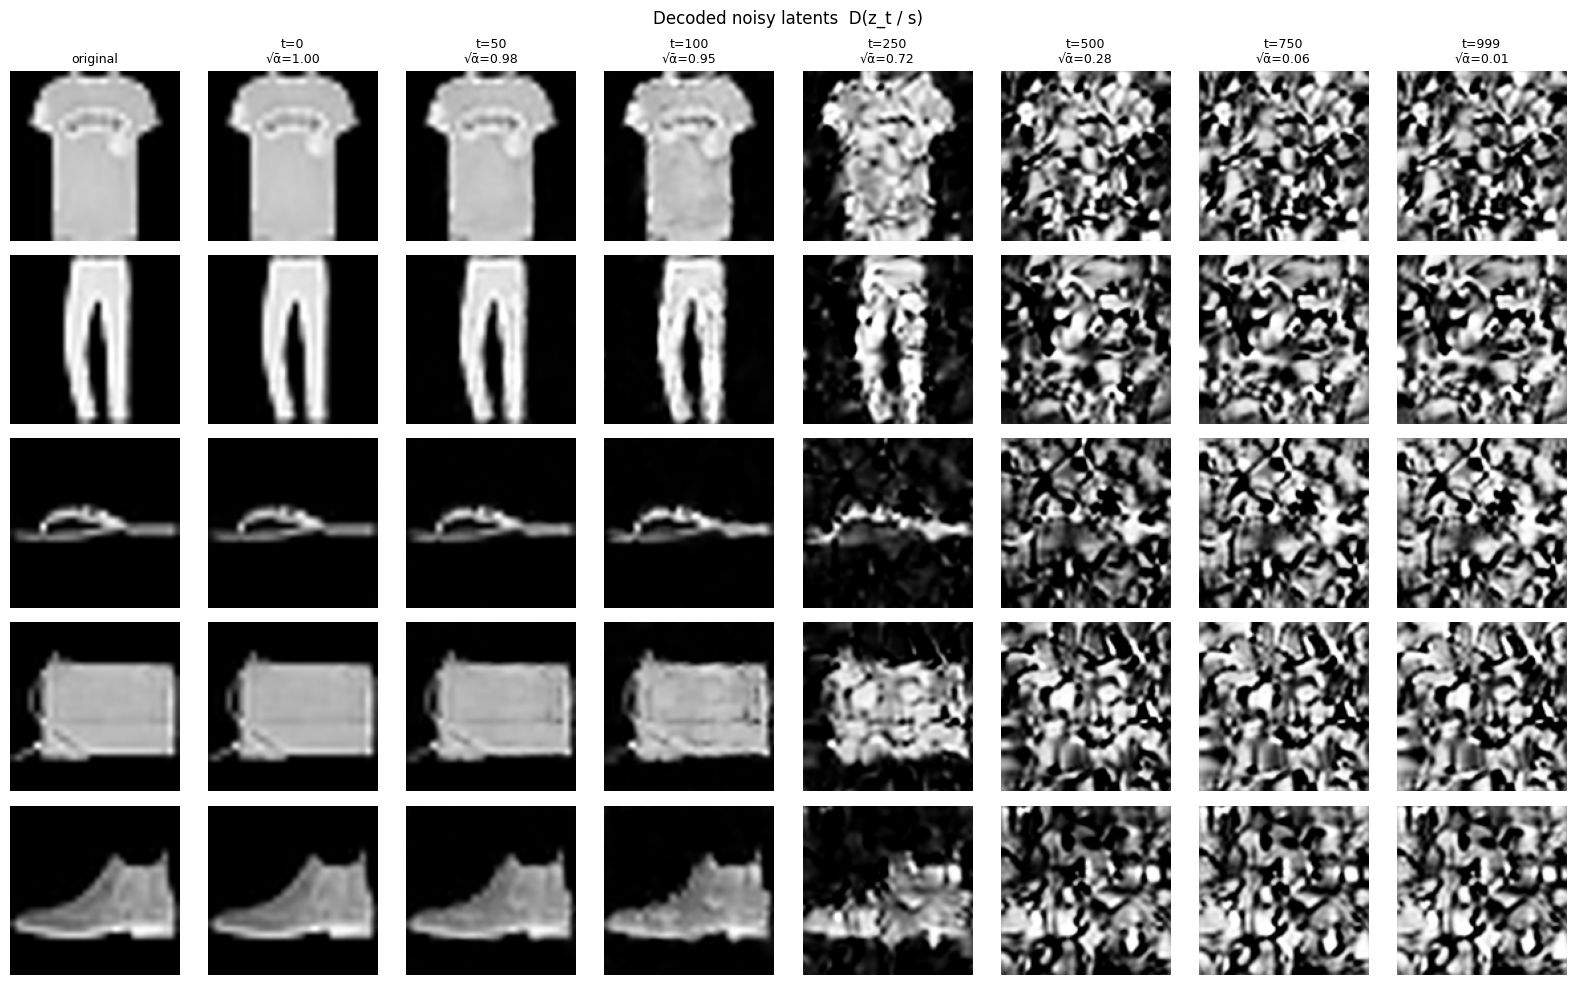

In [8]:
# ----------------------------- visualize decoded noisy latents across timesteps
vis_t = [0, 50, 100, 250, 500, 750, 999]
pick = torch.tensor([(y_test == c).nonzero()[0, 0].item() for c in [0, 1, 5, 8, 9]])
z0 = z_test[pick].to(device)
g = torch.Generator(device=device).manual_seed(0)
eps = torch.randn(z0.shape, generator=g, device=device)

rows = []
for t in vis_t:
    zt, _ = q_sample(z0, torch.full((len(z0),), t, device=device, dtype=torch.long), eps)
    rows.append(to01(vae_decode(zt)).cpu())
imgs = torch.stack(rows, 1)                     # (n_img, n_t, 1, H, W)

fig, axes = plt.subplots(len(pick), len(vis_t) + 1, figsize=(2 * (len(vis_t) + 1), 2 * len(pick)))
for i in range(len(pick)):
    axes[i, 0].imshow(to01(test_set[int(pick[i])][0][0]), cmap="gray"); axes[i, 0].axis("off")
    for j, t in enumerate(vis_t):
        axes[i, j + 1].imshow(imgs[i, j, 0], cmap="gray", vmin=0, vmax=1); axes[i, j + 1].axis("off")
        if i == 0: axes[i, j + 1].set_title(f"t={t}\n√ᾱ={alpha_bars[t].sqrt():.2f}", fontsize=9)
axes[0, 0].set_title("original", fontsize=9)
plt.suptitle("Decoded noisy latents  D(z_t / s)"); plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/forward_diffusion.png", dpi=120, bbox_inches="tight"); plt.show()

**Observation.** Noise added in latent space does not look like pixel-space Gaussian noise once decoded: the decoder maps it to structured, texture-like artifacts. The garment silhouette survives until roughly $t\approx250$ (√ᾱ ≈ 0.8). By $t\approx750$ almost nothing of $z_0$ is left, and at $t=999$ (√ᾱ ≈ 0.006) the latent is essentially pure $\mathcal N(0,I)$, which is the starting point for sampling.

## 3 — Conditional denoising U-Net



In [9]:
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
        args = t.float()[:, None] * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(32, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb   = nn.Sequential(nn.SiLU(), nn.Linear(emb_dim, 2 * out_ch))   # FiLM: scale & shift
        self.norm2 = nn.GroupNorm(32, out_ch)
        self.drop  = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        nn.init.zeros_(self.conv2.weight); nn.init.zeros_(self.conv2.bias)
        self.skip  = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.emb(emb)[:, :, None, None].chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale) + shift
        h = self.conv2(self.drop(F.silu(h)))
        return h + self.skip(x)


class AttnBlock(nn.Module):
    # Multi-head self-attention over spatial positions (+ optional cross-attention to label tokens)
    def __init__(self, ch, ctx_dim=None, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(32, ch)
        self.self_attn = nn.MultiheadAttention(ch, heads, batch_first=True)
        self.cross_attn = None
        if ctx_dim is not None:
            self.norm_c = nn.LayerNorm(ch)
            self.cross_attn = nn.MultiheadAttention(ch, heads, kdim=ctx_dim, vdim=ctx_dim, batch_first=True)

    def forward(self, x, ctx=None):
        B, C, H, W = x.shape
        s = x.flatten(2).transpose(1, 2)                         # (B, HW, C)
        n = self.norm(x).flatten(2).transpose(1, 2)
        s = s + self.self_attn(n, n, n, need_weights=False)[0]
        if self.cross_attn is not None and ctx is not None:
            n = self.norm_c(s)
            s = s + self.cross_attn(n, ctx, ctx, need_weights=False)[0]
        return s.transpose(1, 2).reshape(B, C, H, W)


class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__(); self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x): return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__(); self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x): return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class EmbedSequential(nn.Sequential):
    # Routes the right conditioning to each layer type
    def forward(self, x, emb, ctx):
        for layer in self:
            if isinstance(layer, ResBlock):   x = layer(x, emb)
            elif isinstance(layer, AttnBlock): x = layer(x, ctx)
            else:                              x = layer(x)
        return x


class ConditionalUNet(nn.Module):
    def __init__(self, in_ch=4, base_ch=64, ch_mults=(1, 2, 4), num_res_blocks=2, attn_res=(16,),
                 latent_size=16, num_classes=10, emb_dim=256, ctx_tokens=4, use_cross_attn=True, dropout=0.1):
        super().__init__()
        self.num_classes, self.ctx_tokens, self.emb_dim = num_classes, ctx_tokens, emb_dim
        ctx_dim = emb_dim if use_cross_attn else None

        # time embedding: sinusoidal + MLP
        self.time_mlp = nn.Sequential(SinusoidalPosEmb(base_ch), nn.Linear(base_ch, emb_dim),
                                      nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        # label embedding: 10 classes + 1 null label (index = num_classes)
        self.label_emb = nn.Embedding(num_classes + 1, emb_dim)
        self.ctx_emb = nn.Embedding(num_classes + 1, ctx_tokens * emb_dim) if use_cross_attn else None

        self.in_conv = nn.Conv2d(in_ch, base_ch, 3, padding=1)

        # ---------------- encoder
        self.downs = nn.ModuleList()
        skip_chs, ch, res = [base_ch], base_ch, latent_size
        for lvl, m in enumerate(ch_mults):
            out = base_ch * m
            for _ in range(num_res_blocks):
                layers = [ResBlock(ch, out, emb_dim, dropout)]; ch = out
                if res in attn_res: layers.append(AttnBlock(ch, ctx_dim))
                self.downs.append(EmbedSequential(*layers)); skip_chs.append(ch)
            if lvl != len(ch_mults) - 1:
                self.downs.append(EmbedSequential(Downsample(ch))); skip_chs.append(ch); res //= 2

        # ---------------- bottleneck (with self-attention)
        self.mid = EmbedSequential(ResBlock(ch, ch, emb_dim, dropout), AttnBlock(ch, ctx_dim),
                                   ResBlock(ch, ch, emb_dim, dropout))

        # ---------------- decoder with skip connections
        self.ups = nn.ModuleList()
        for lvl, m in reversed(list(enumerate(ch_mults))):
            out = base_ch * m
            for i in range(num_res_blocks + 1):
                layers = [ResBlock(ch + skip_chs.pop(), out, emb_dim, dropout)]; ch = out
                if res in attn_res: layers.append(AttnBlock(ch, ctx_dim))
                if lvl != 0 and i == num_res_blocks:
                    layers.append(Upsample(ch)); res *= 2
                self.ups.append(EmbedSequential(*layers))
        assert not skip_chs

        self.out = nn.Sequential(nn.GroupNorm(32, ch), nn.SiLU(), nn.Conv2d(ch, in_ch, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight); nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, y):
        emb = self.time_mlp(t) + self.label_emb(y)                      # combine label + time
        ctx = None
        if self.ctx_emb is not None:
            ctx = self.ctx_emb(y).view(x.shape[0], self.ctx_tokens, self.emb_dim)
        h = self.in_conv(x); hs = [h]
        for blk in self.downs:
            h = blk(h, emb, ctx); hs.append(h)
        h = self.mid(h, emb, ctx)
        for blk in self.ups:
            h = blk(torch.cat([h, hs.pop()], dim=1), emb, ctx)
        return self.out(h)


model = ConditionalUNet(in_ch=LATENT_SHAPE[0], base_ch=CFG["base_ch"], ch_mults=CFG["ch_mults"],
                        num_res_blocks=CFG["num_res_blocks"], attn_res=CFG["attn_res"],
                        latent_size=LATENT_SHAPE[-1], num_classes=CFG["num_classes"], emb_dim=CFG["emb_dim"],
                        ctx_tokens=CFG["ctx_tokens"], use_cross_attn=CFG["use_cross_attn"],
                        dropout=CFG["dropout"]).to(device)
print(f"U-Net parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

# shape / attention-placement sanity check
with torch.no_grad():
    _z = torch.randn(2, *LATENT_SHAPE, device=device)
    _o = model(_z, torch.tensor([0, 999], device=device), torch.tensor([3, NULL_LABEL], device=device))
assert _o.shape == _z.shape
attn_where = []
_hooks = [m.register_forward_hook(lambda mod, inp, out: attn_where.append(tuple(inp[0].shape[-2:])))
          for m in model.modules() if isinstance(m, AttnBlock)]
with torch.no_grad(): model(_z, torch.tensor([0, 1], device=device), torch.tensor([0, 1], device=device))
for h in _hooks: h.remove()
print("output shape:", tuple(_o.shape), "| attention blocks at resolutions:", attn_where)

U-Net parameters: 15.68M
output shape: (2, 4, 16, 16) | attention blocks at resolutions: [(16, 16), (16, 16), (4, 4), (16, 16), (16, 16), (16, 16)]


## 4 & 5 — Classifier-free guidance training



In [10]:
train_loader = DataLoader(TensorDataset(z_train, y_train), batch_size=CFG["batch_size"],
                          shuffle=True, drop_last=True, num_workers=2, pin_memory=True)

opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=0.0)
ema = copy.deepcopy(model).eval().requires_grad_(False)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
CKPT = os.path.join(CFG["out_dir"], "ldm_unet_ckpt.pt")

# fixed validation batch (same t / noise every epoch -> comparable numbers)
gv = torch.Generator().manual_seed(123)
val_idx = torch.randperm(len(z_test), generator=gv)[:2048]
val_z, val_y = z_test[val_idx].to(device), y_test[val_idx].to(device)
val_t = torch.randint(0, T, (len(val_z),), generator=gv).to(device)
val_eps = torch.randn(val_z.shape, generator=gv).to(device)

@torch.no_grad()
def val_loss(net):
    net.eval(); tot = 0.
    for s in range(0, len(val_z), 512):
        zt, _ = q_sample(val_z[s:s+512], val_t[s:s+512], val_eps[s:s+512])
        tot += F.mse_loss(net(zt, val_t[s:s+512], val_y[s:s+512]), val_eps[s:s+512], reduction="sum").item()
    return tot / val_eps.numel()

@torch.no_grad()
def ema_update(step):
    d = min(CFG["ema_decay"], (1 + step) / (10 + step))
    for pe, p in zip(ema.parameters(), model.parameters()):
        pe.mul_(d).add_(p.detach(), alpha=1 - d)

history = dict(train=[], val=[], val_ema=[], time=[])
start_epoch, step = 0, 0
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
    scaler.load_state_dict(ck["scaler"]); history = ck["history"]; start_epoch, step = ck["epoch"] + 1, ck["step"]
    print(f"Resumed from epoch {start_epoch}")

In [11]:
for epoch in range(start_epoch, CFG["epochs"]):
    model.train(); t0 = time.time(); run, nb = 0., 0
    for z0, y in train_loader:
        z0, y = z0.to(device, non_blocking=True), y.to(device, non_blocking=True)
        t = torch.randint(0, T, (z0.shape[0],), device=device)
        zt, noise = q_sample(z0, t)
        # classifier-free guidance: drop labels -> null label with prob p_uncond
        drop = torch.rand(z0.shape[0], device=device) < CFG["p_uncond"]
        y_in = torch.where(drop, torch.full_like(y, NULL_LABEL), y)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            pred = model(zt, t, y_in)
        loss = F.mse_loss(pred.float(), noise)

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        ema_update(step); step += 1
        run += loss.item(); nb += 1

    history["train"].append(run / nb); history["val"].append(val_loss(model))
    history["val_ema"].append(val_loss(ema)); history["time"].append(time.time() - t0)
    torch.save(dict(model=model.state_dict(), ema=ema.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(),
                    history=history, epoch=epoch, step=step, cfg=CFG), CKPT)
    print(f"epoch {epoch+1:3d}/{CFG['epochs']} | train {history['train'][-1]:.4f} | val {history['val'][-1]:.4f} "
          f"| val(EMA) {history['val_ema'][-1]:.4f} | {history['time'][-1]:.0f}s")

torch.save(dict(ema=ema.state_dict(), cfg=CFG), os.path.join(CFG["out_dir"], "ldm_unet_ema_final.pt"))
print(f"Total training time: {sum(history['time'])/60:.1f} min")

epoch   1/50 | train 0.6686 | val 0.3797 | val(EMA) 0.4221 | 72s
epoch   2/50 | train 0.2631 | val 0.1783 | val(EMA) 0.1988 | 71s
epoch   3/50 | train 0.1586 | val 0.1351 | val(EMA) 0.1416 | 69s
epoch   4/50 | train 0.1347 | val 0.1239 | val(EMA) 0.1266 | 70s
epoch   5/50 | train 0.1254 | val 0.1189 | val(EMA) 0.1204 | 70s
epoch   6/50 | train 0.1219 | val 0.1158 | val(EMA) 0.1168 | 70s
epoch   7/50 | train 0.1198 | val 0.1132 | val(EMA) 0.1141 | 70s
epoch   8/50 | train 0.1175 | val 0.1111 | val(EMA) 0.1120 | 70s
epoch   9/50 | train 0.1147 | val 0.1096 | val(EMA) 0.1102 | 69s
epoch  10/50 | train 0.1145 | val 0.1084 | val(EMA) 0.1087 | 69s
epoch  11/50 | train 0.1112 | val 0.1066 | val(EMA) 0.1073 | 71s
epoch  12/50 | train 0.1112 | val 0.1057 | val(EMA) 0.1061 | 71s
epoch  13/50 | train 0.1093 | val 0.1044 | val(EMA) 0.1050 | 71s
epoch  14/50 | train 0.1082 | val 0.1034 | val(EMA) 0.1040 | 71s
epoch  15/50 | train 0.1064 | val 0.1025 | val(EMA) 0.1031 | 71s
epoch  16/50 | train 0.10

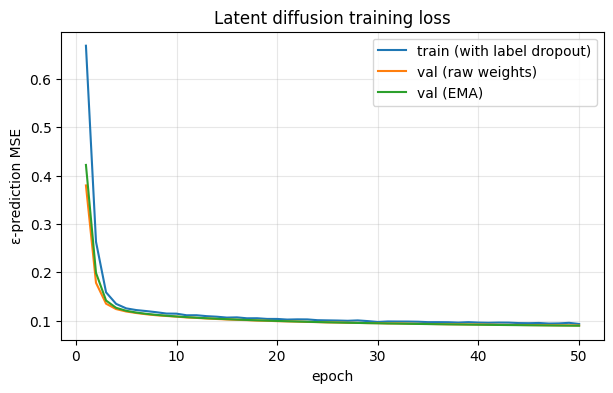

In [12]:
ep = np.arange(1, len(history["train"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(ep, history["train"], label="train (with label dropout)")
plt.plot(ep, history["val"], label="val (raw weights)"); plt.plot(ep, history["val_ema"], label="val (EMA)")
plt.xlabel("epoch"); plt.ylabel("ε-prediction MSE"); plt.title("Latent diffusion training loss"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{CFG['out_dir']}/loss_curve.png", dpi=120, bbox_inches="tight"); plt.show()

## 6 — Sampling with classifier-free guidance


In [13]:
@torch.no_grad()
def sample_cfg(net, labels, w=CFG["guidance_scale"], seed=0, chunk=256, traj_steps=()):
    # DDPM ancestral sampling with classifier-free guidance. Returns scaled latents (+ optional trajectory).
    net.eval()
    labels = torch.as_tensor(labels, device=device, dtype=torch.long)
    g = torch.Generator(device=device).manual_seed(seed)
    out, traj = [], {s: [] for s in traj_steps}
    for yc in labels.split(chunk):
        n = len(yc)
        z = torch.randn((n, *LATENT_SHAPE), generator=g, device=device)
        yu = torch.full_like(yc, NULL_LABEL)
        for t in reversed(range(T)):
            tt = torch.full((2 * n,), t, device=device, dtype=torch.long)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                e = net(torch.cat([z, z]), tt, torch.cat([yc, yu])).float()
            eps_c, eps_u = e.chunk(2)                       # conditional & unconditional predictions
            eps = eps_u + w * (eps_c - eps_u)               # CFG combination
            a, ab, b = sched["alphas"][t], sched["alpha_bars"][t], sched["betas"][t]
            mean = (z - b / (1 - ab).sqrt() * eps) / a.sqrt()
            if t > 0:
                z = mean + sched["post_var"][t].sqrt() * torch.randn(z.shape, generator=g, device=device)
            else:
                z = mean
            if t in traj: traj[t].append(z.clone())
        out.append(z)
    z = torch.cat(out)
    return (z, {k: torch.cat(v) for k, v in traj.items()}) if traj_steps else z

def show_grid(imgs01, labels, nrow, title, path=None):
    n = len(imgs01); ncol = math.ceil(n / nrow)
    fig, axes = plt.subplots(ncol, nrow, figsize=(1.6 * nrow, 1.75 * ncol))
    for i, ax in enumerate(np.array(axes).reshape(-1)):
        ax.axis("off")
        if i < n:
            ax.imshow(imgs01[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            if labels is not None: ax.set_title(CLASSES[int(labels[i])], fontsize=7)
    plt.suptitle(title); plt.tight_layout()
    if path: plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()

Sampled 64 images (1000 steps, CFG w=3.0) in 44s


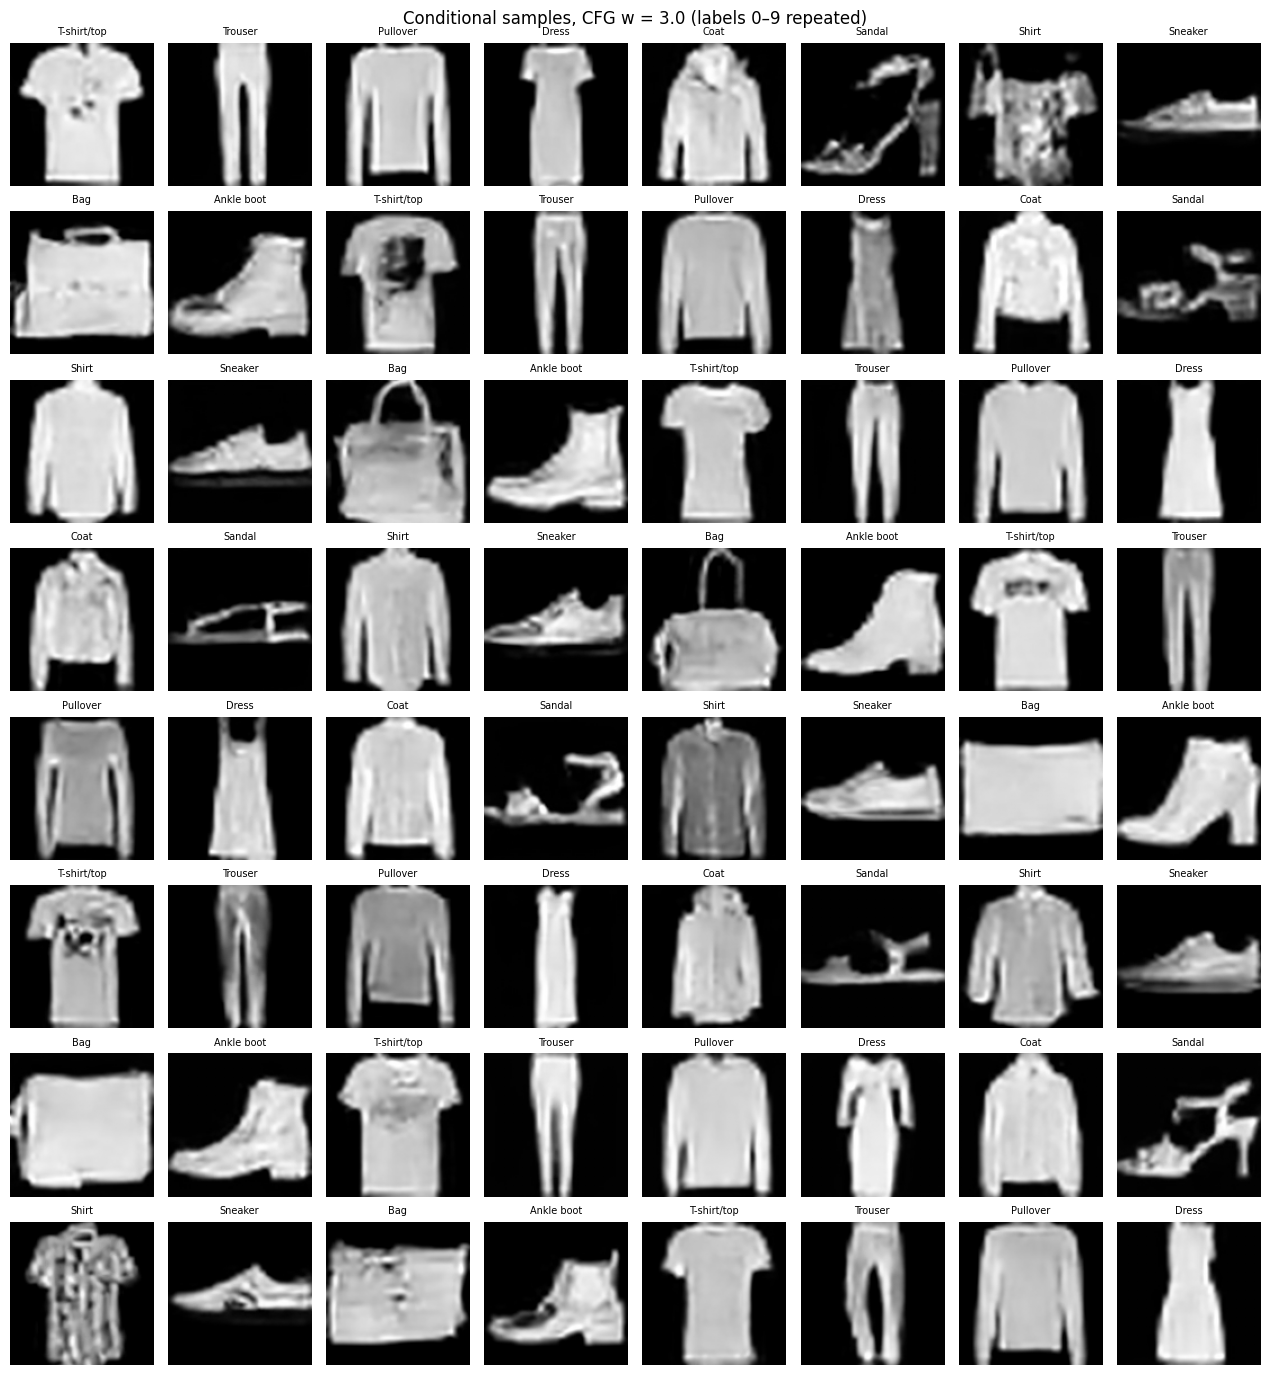

In [14]:
# ----------------------------- 64-image conditional grid, labels 0..9 repeated
grid_labels = torch.arange(64) % 10
t0 = time.time()
z_gen, traj = sample_cfg(ema, grid_labels, w=CFG["guidance_scale"], seed=CFG["seed"],
                         traj_steps=(999, 750, 500, 250, 100, 0))
x_gen = to01(vae_decode(z_gen))
print(f"Sampled 64 images (1000 steps, CFG w={CFG['guidance_scale']}) in {time.time()-t0:.0f}s")
show_grid(x_gen, grid_labels, 8, f"Conditional samples, CFG w = {CFG['guidance_scale']} (labels 0–9 repeated)",
          f"{CFG['out_dir']}/conditional_grid_64.png")

# compact version as a single image
torchvision.utils.save_image(make_grid(x_gen, nrow=8, pad_value=1), f"{CFG['out_dir']}/conditional_grid_64_plain.png")

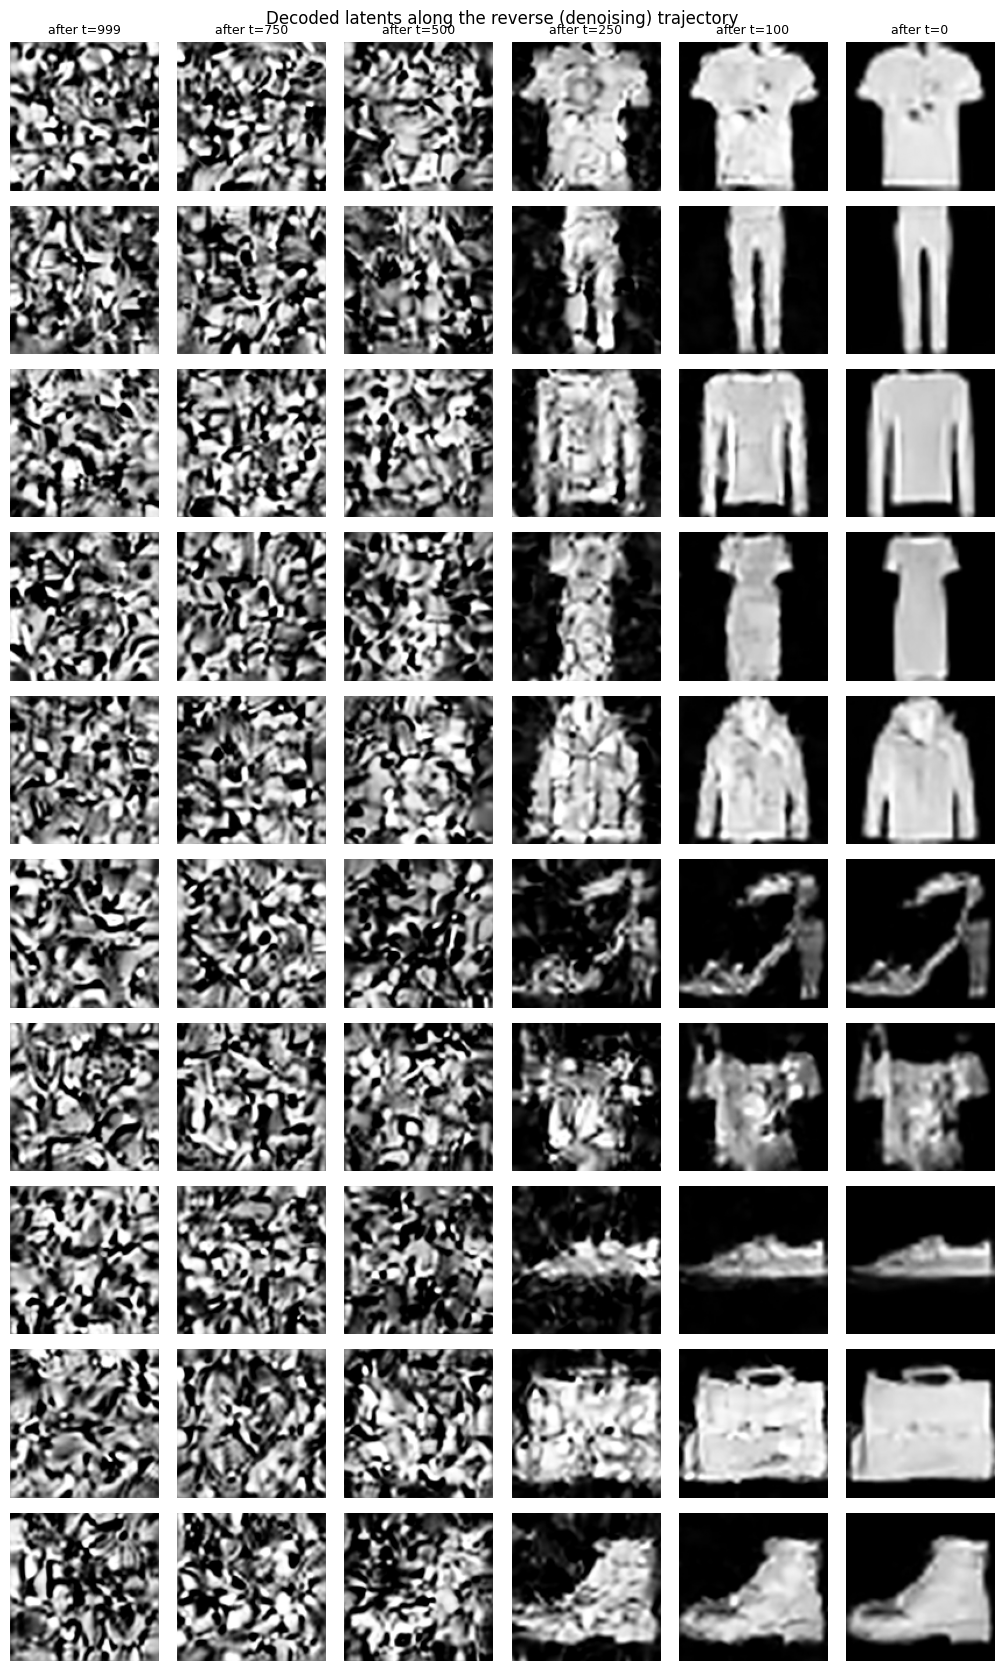

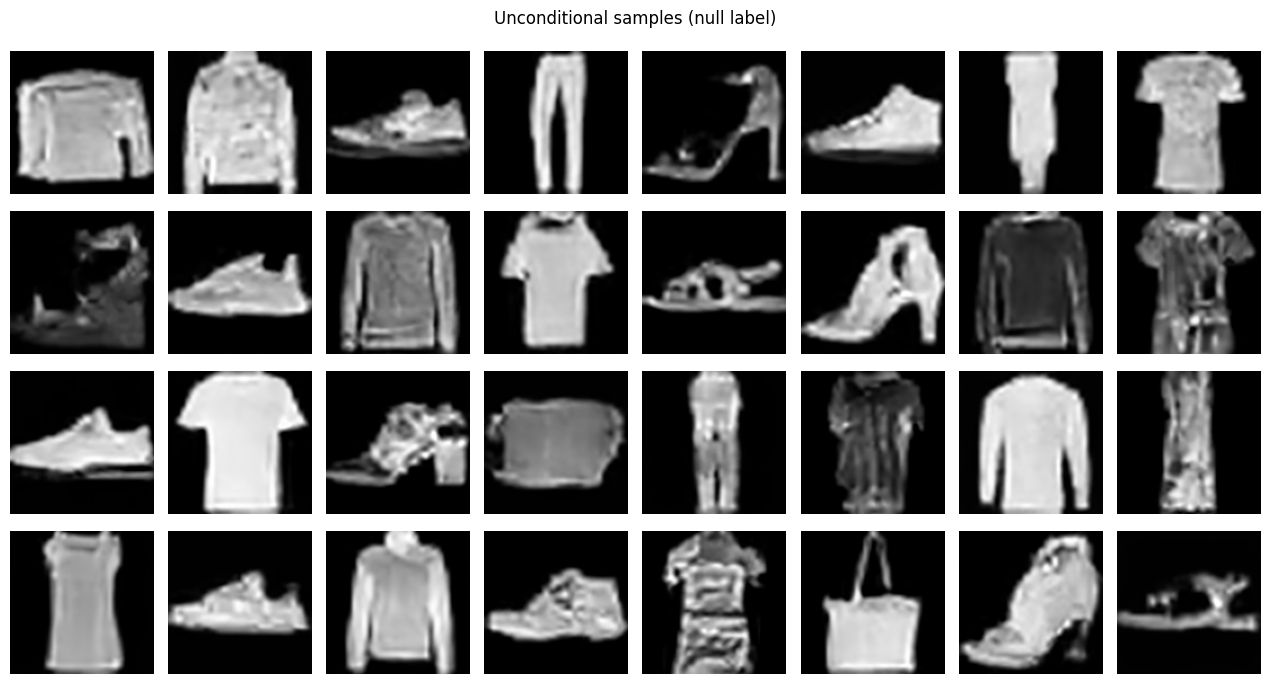

In [15]:
# ----------------------------- reverse-process trajectory (first 10 samples = one per class)
steps = sorted(traj.keys(), reverse=True)
fig, axes = plt.subplots(10, len(steps), figsize=(1.7 * len(steps), 17))
for j, s in enumerate(steps):
    dec = to01(vae_decode(traj[s][:10]))
    for i in range(10):
        axes[i, j].imshow(dec[i, 0].cpu(), cmap="gray", vmin=0, vmax=1); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(f"after t={s}", fontsize=9)
plt.suptitle("Decoded latents along the reverse (denoising) trajectory"); plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/reverse_trajectory.png", dpi=110, bbox_inches="tight"); plt.show()

# ----------------------------- unconditional samples (null label only, w irrelevant)
z_unc = sample_cfg(ema, torch.full((32,), NULL_LABEL), w=0.0, seed=1)
show_grid(to01(vae_decode(z_unc)), None, 8, "Unconditional samples (null label)", f"{CFG['out_dir']}/unconditional_grid.png")

## 7 — Evaluation & analysis



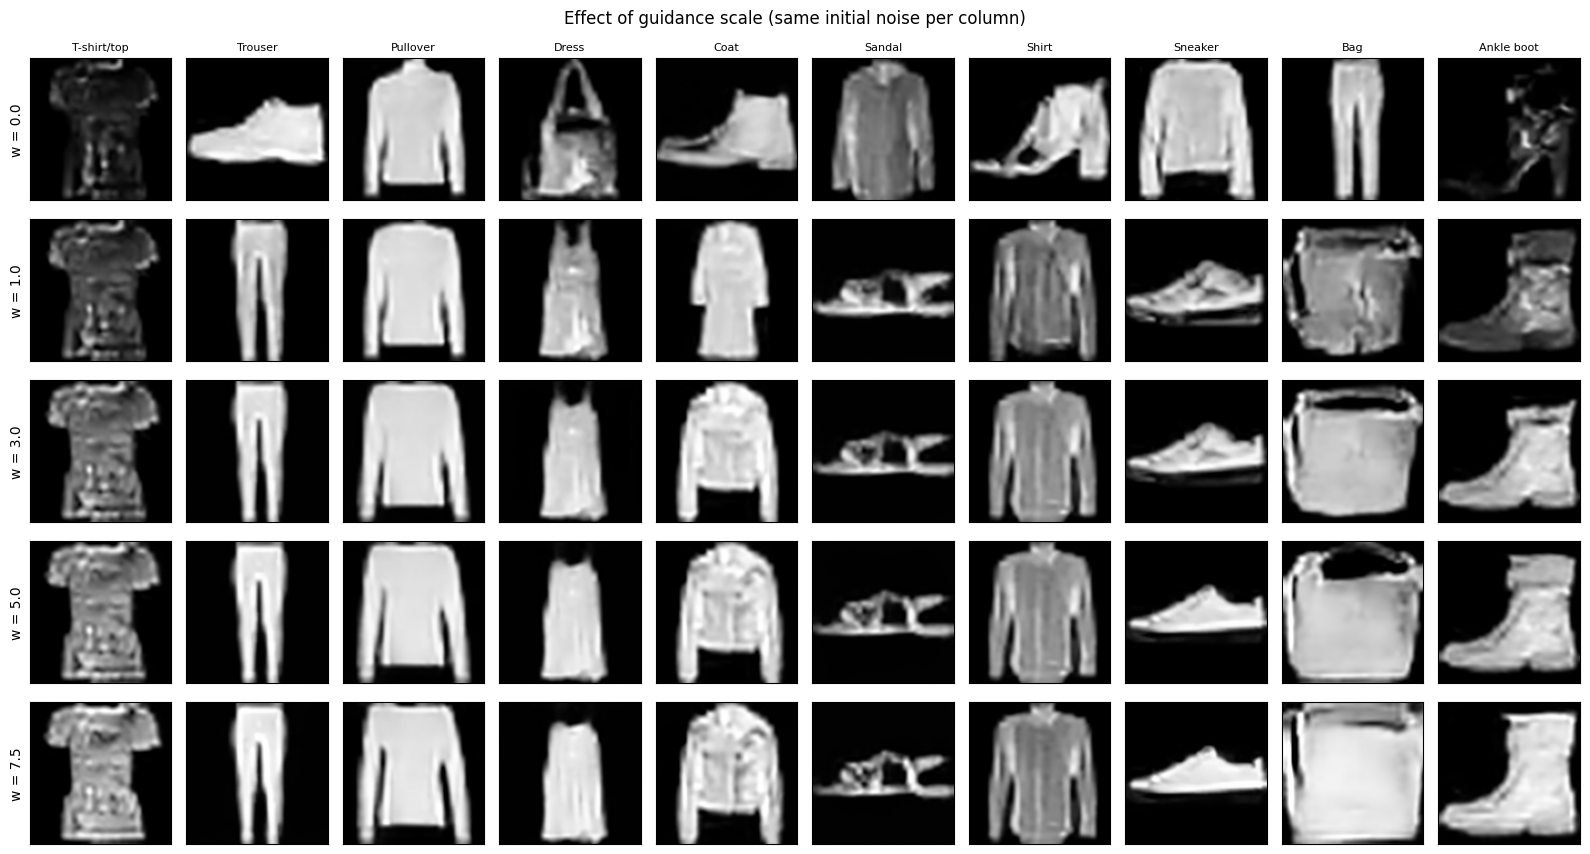

In [16]:
sweep_w = [0.0, 1.0, 3.0, 5.0, 7.5]
lab10 = torch.arange(10)
fig, axes = plt.subplots(len(sweep_w), 10, figsize=(16, 1.75 * len(sweep_w)))
for r, w in enumerate(sweep_w):
    xs = to01(vae_decode(sample_cfg(ema, lab10, w=w, seed=7)))
    for c in range(10):
        axes[r, c].imshow(xs[c, 0].cpu(), cmap="gray", vmin=0, vmax=1); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(CLASSES[c], fontsize=8)
    axes[r, 0].set_ylabel(f"w = {w}", fontsize=10)
plt.suptitle("Effect of guidance scale (same initial noise per column)"); plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/guidance_sweep.png", dpi=120, bbox_inches="tight"); plt.show()

In [17]:
# ----------------------------- evaluation classifier on real 28x28 data
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(blk(1, 32), blk(32, 64), nn.Flatten(), nn.Linear(64 * 7 * 7, 256), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, 10))
    def forward(self, x, return_feat=False):
        f = self.features(x)
        return (self.head(f), f) if return_feat else self.head(f)

norm28 = lambda x01: (x01 - 0.5) / 0.5
raw_train = datasets.FashionMNIST("data", train=True, download=True, transform=transforms.ToTensor())
clf_loader = DataLoader(raw_train, batch_size=256, shuffle=True, num_workers=2)
clf = SmallCNN().to(device); copt = torch.optim.Adam(clf.parameters(), 1e-3)
for e in range(6):
    clf.train()
    for x, y in clf_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(clf(norm28(x)), y); copt.zero_grad(); loss.backward(); copt.step()
clf.eval()

@torch.no_grad()
def classify(x01_28, bs=500):
    logits, feats = [], []
    for xb in x01_28.split(bs):
        l, f = clf(norm28(xb.to(device)), return_feat=True); logits.append(l); feats.append(f)
    return torch.cat(logits), torch.cat(feats)

real_x = torch.stack([raw_test[i][0] for i in range(len(raw_test))])
real_logits, real_feats = classify(real_x)
print(f"Evaluation classifier accuracy on real test set: {(real_logits.argmax(1).cpu() == y_test).float().mean():.4f}")

Evaluation classifier accuracy on real test set: 0.9204


In [18]:
from scipy import linalg

def frechet(f1, f2):
    f1, f2 = f1.double().cpu().numpy(), f2.double().cpu().numpy()
    mu1, mu2 = f1.mean(0), f2.mean(0); s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
    covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

def diversity(x01, labels):
    return float(np.mean([x01[labels == c].std(0).mean().item() for c in labels.unique()]))

PER_CLASS = 100                     # 1000 samples per setting; lower it to save time
eval_labels = torch.arange(10).repeat_interleave(PER_CLASS)
results, gen_store = {}, {}

# reference: VAE reconstructions of real test images (same decode -> 28x28 path)
rec_idx = torch.cat([(y_test == c).nonzero()[:PER_CLASS, 0] for c in range(10)])
x_rec = to28(to01(vae_decode(z_test[rec_idx].to(device)))).cpu()
l, f = classify(x_rec)
results["VAE recon (ref)"] = dict(acc=(l.argmax(1).cpu() == y_test[rec_idx]).float().mean().item(),
                                  fd=frechet(f, real_feats), div=diversity(x_rec, y_test[rec_idx]))

for w in [0.0, 1.0, 3.0, 5.0, 7.5]:
    t0 = time.time()
    xg = to28(to01(vae_decode(sample_cfg(ema, eval_labels, w=w, seed=100)))).cpu()
    l, f = classify(xg); gen_store[w] = (xg, l.argmax(1).cpu())
    results[f"w = {w}"] = dict(acc=(l.argmax(1).cpu() == eval_labels).float().mean().item(),
                               fd=frechet(f, real_feats), div=diversity(xg, eval_labels))
    print(f"w={w}: done in {time.time()-t0:.0f}s")

print(f"\n{'setting':18s} {'class acc':>10s} {'Fréchet dist':>13s} {'diversity':>10s}")
for k, v in results.items():
    print(f"{k:18s} {v['acc']:10.3f} {v['fd']:13.2f} {v['div']:10.4f}")
print("(w = 0 is unconditional: its 'class acc' is chance-level by construction, ~0.1)")

/tmp/ipykernel_543/3155628404.py:6: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
/tmp/ipykernel_543/3155628404.py:6: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)


w=0.0: done in 736s
w=1.0: done in 737s
w=3.0: done in 737s
w=5.0: done in 736s
w=7.5: done in 737s

setting             class acc  Fréchet dist  diversity
VAE recon (ref)         0.909         62.06     0.1747
w = 0.0                 0.078        152.68     0.2516
w = 1.0                 0.858        124.82     0.1668
w = 3.0                 0.992         90.75     0.1390
w = 5.0                 0.998        101.39     0.1373
w = 7.5                 0.990        127.48     0.1556
(w = 0 is unconditional: its 'class acc' is chance-level by construction, ~0.1)


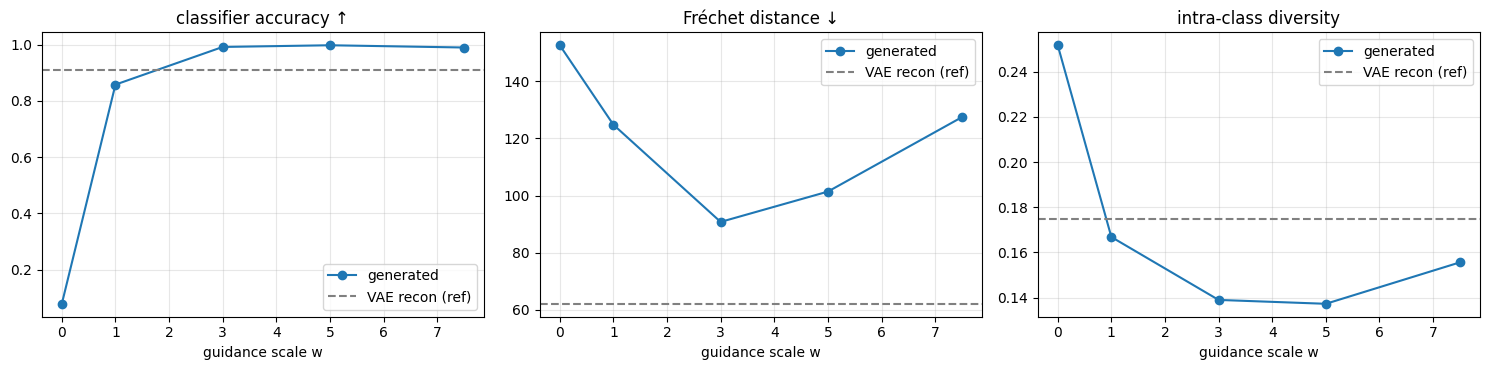

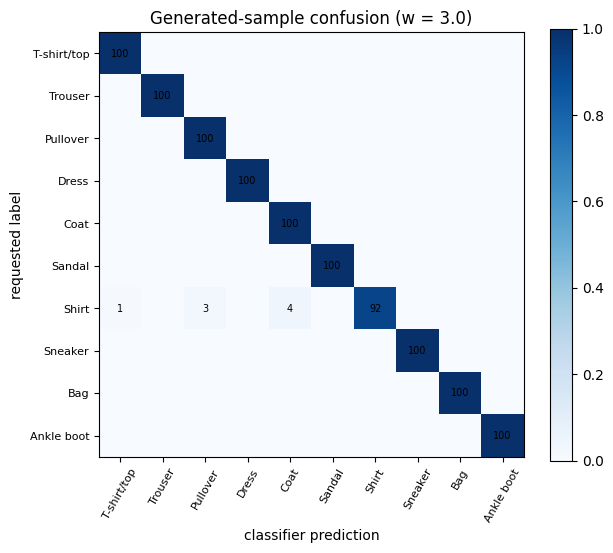

per-class accuracy: {'T-shirt/top': 1.0, 'Trouser': 1.0, 'Pullover': 1.0, 'Dress': 1.0, 'Coat': 1.0, 'Sandal': 1.0, 'Shirt': 0.92, 'Sneaker': 1.0, 'Bag': 1.0, 'Ankle boot': 1.0}


In [19]:
ws = [0.0, 1.0, 3.0, 5.0, 7.5]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, key, name in zip(ax, ["acc", "fd", "div"], ["classifier accuracy ↑", "Fréchet distance ↓", "intra-class diversity"]):
    a.plot(ws, [results[f"w = {w}"][key] for w in ws], "o-", label="generated")
    a.axhline(results["VAE recon (ref)"][key], ls="--", c="gray", label="VAE recon (ref)")
    a.set_xlabel("guidance scale w"); a.set_title(name); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/guidance_metrics.png", dpi=120, bbox_inches="tight"); plt.show()

# confusion matrix at the chosen guidance scale
xg, pred = gen_store[CFG["guidance_scale"]]
cm = torch.zeros(10, 10)
for t_, p_ in zip(eval_labels, pred): cm[t_, p_] += 1
plt.figure(figsize=(6.5, 5.5)); plt.imshow(cm / PER_CLASS, cmap="Blues", vmin=0, vmax=1); plt.colorbar()
plt.xticks(range(10), CLASSES, rotation=60, fontsize=8); plt.yticks(range(10), CLASSES, fontsize=8)
plt.xlabel("classifier prediction"); plt.ylabel("requested label")
plt.title(f"Generated-sample confusion (w = {CFG['guidance_scale']})")
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0: plt.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()
per_class = (cm.diag() / PER_CLASS).tolist()
print("per-class accuracy:", {CLASSES[i]: round(a, 2) for i, a in enumerate(per_class)})

### Analysis

**Run summary (Colab T4).** VAE encoding of 70,000 images took 16 min, training 50 epochs × ~70 s took 58 min, and evaluation sampling took 5 × 12.3 min ≈ 61 min. The U-Net has 15.68M parameters, with attention at 16×16 (2 encoder + 3 decoder blocks) and at the 4×4 bottleneck.

**VAE compression.** Each 128×128 image becomes a 4×16×16 latent (1,024 values). That is a 16× reduction from the grayscale image, or 48× from the 3-channel input the VAE actually sees. Reconstruction is nearly lossless:

| comparison (2,000 test images, pixels in [0,1]) | MSE | PSNR |
|---|---|---|
| 128×128 VAE input vs. reconstruction | 0.00016 | 38.06 dB |
| 28×28 (downsampled) vs. downsampled reconstruction | 0.00005 | 42.88 dB |
| native 28×28 original vs. downsampled reconstruction | 0.00219 | — |

The error maps are dark except along fine high-frequency detail: knit textures, printed logos, and garment edges. The larger error against the *native* 28×28 image (0.00219) comes mostly from the bicubic up-/down-sampling round trip, not from the VAE. The evaluation classifier gets 90.9% on VAE reconstructions vs. 92.0% on real images, so the compression keeps almost all class information. With the standard factor 0.18215 the scaled latents have mean −0.040 and std 1.27, not exactly 1, because the factor was fit on natural images. The per-channel std is also uneven (1.15, 1.39, 0.60, 0.72). The latent channel maps clearly follow the garment's silhouette, so the latent stays spatially aligned with the image.

**Forward process.** In the decoded noisy latents, t ≤ 100 (√ᾱ ≥ 0.95) is visually indistinguishable from the original. At t = 250 (√ᾱ = 0.72) the silhouette is still recognisable, but it is already broken up by blotchy texture. By t = 500 (√ᾱ = 0.28) the image is gone. t = 750 (0.06) and t = 999 (0.01) are effectively pure noise. Latent noise does not decode to pixel "snow". The decoder turns it into structured, swirling texture, because it interprets every latent as image content. The SNR plot shows the linear schedule spends roughly half its steps below SNR = 1.

**Training.** Training loss falls from 0.669 to 0.093, and validation loss from 0.380 to 0.090 (EMA: 0.0895). Most of the drop happens in the first 5 epochs (val 0.38 → 0.12). After that it improves slowly and steadily, and is still falling at epoch 50, so the model is not fully converged at LR 2e-5. Training loss stays above validation loss because training runs with dropout and 10% label dropout, while validation is in eval mode with true labels. There is no sign of overfitting. The EMA weights lag behind early on (worse until epoch ~26) and are better for the rest of training.

**Reverse process.** The denoising trajectory mirrors the forward process. Decoded latents are pure texture at t = 999, 750 and 500. The garment shape appears between t = 500 and t = 250. By t = 100 the sample is essentially final; the last 100 steps only sharpen detail. The 64-image conditional grid (w = 3) shows a recognisable item of the requested class in every cell. The weakest samples are Shirts and patterned T-shirts, which show blotchy texture artifacts.

**Classifier-free guidance.**

| setting | class accuracy | Fréchet distance ↓ | intra-class diversity |
|---|---|---|---|
| VAE recon (reference) | 0.909 | 62.06 | 0.175 |
| w = 0 (unconditional) | 0.078 | 152.68 | 0.252 |
| w = 1 (conditional) | 0.858 | 124.82 | 0.167 |
| **w = 3 (used)** | **0.992** | **90.75** | 0.139 |
| w = 5 | 0.998 | 101.39 | 0.137 |
| w = 7.5 | 0.990 | 127.48 | 0.156 |

* **w = 0** ignores the label. In the guidance sweep, the "Trouser" column produces a sneaker, "Dress" a bag, and "Bag" trousers. Accuracy is 7.8%, at chance (10%). This confirms the null label carries no class information. Its diversity score is inflated because the samples it is computed over are of mixed classes.
* **w = 1** mostly follows the label (85.8%), but some samples are ambiguous: the Coat looks dress-like and the Bag is malformed.
* **w = 3** gives the best balance. Accuracy is 99.2%, and the Fréchet distance reaches its minimum of 90.75: 41% better than w = 0 and 27% better than w = 1. Accuracy above the classifier's 92.0% on real data does not mean the samples are better than real. It means guided samples are *prototypical*: they sit far from class boundaries and avoid the ambiguous cases real test images contain.
* **Too much guidance.** At w = 5 and 7.5, accuracy saturates (99.8%) but the Fréchet distance rises again (101.4, then 127.5). In the sweep, samples become smoother, brighter and more uniform: the sneaker turns into a flat white shape and the bag into a bright box with no texture. Diversity falls from 0.167 (w = 1) to 0.137 (w = 5), below the real-data reference of 0.175. Its small rise at w = 7.5 (0.156) comes from high-contrast artifacts, not real variety.
* This is the classic CFG fidelity/diversity trade-off.
* **Per-class accuracy at w = 3:** 100% for 9 of 10 classes. **Shirt** is the only exception at 92%: 4 of its 100 samples are classified as Coat, 3 as Pullover, and 1 as T-shirt/top. Those are exactly the visually overlapping upper-body classes, which are also the hardest classes for classifiers on real Fashion-MNIST. Part of this error is therefore due to the evaluator, not only the generator.
* The best generated Fréchet distance (90.75) is still above the VAE-reconstruction floor (62.06), so the diffusion model itself still has room to improve. More training would help, since the loss was still decreasing.

**Cost of CFG.** Each of the 1000 reverse steps runs the U-Net on a doubled batch (conditional + unconditional together), so guided sampling costs 2× an unguided pass. Generating 64 images took 44 s, and 1,000 images took ~12.3 min on a T4, dominated by the 1000 DDPM steps. A DDIM sampler with ~50 steps would cut this by roughly 20×.

**Limitations.**
* Only one diffusion configuration was trained, as the assignment allows.
* The Fréchet distance uses a task-specific 256-d classifier feature space, so it is not comparable to published FID values. SciPy warned that the feature covariance is singular (some ReLU features are always zero), so the absolute Fréchet values are approximate. The ranking across guidance scales is still meaningful.
* The VAE was pretrained on RGB natural images, and its reconstructions cap achievable sample quality.
* The standard scaling factor leaves the latents at std 1.27 rather than 1. A dataset-specific factor (≈ 0.143) could improve diffusion training.